# CP-SAT

Static CP-SAT model (`math/12_cp-sat.md`) on the toy instance and mk01, and the best dispatching rule vs. CP-SAT
with cold and warm start on all Brandimarte instances.

In [ ]:
%matplotlib inline
from pathlib import Path

import simulation
from simulation.check.feasibility import check_schedule
from simulation.io.brandimarte_loader import load_fjs
from simulation.io.json_loader import read_model
from simulation.model.compiled import compile_instance
from simulation.model.instance import Instance
from simulation.viz import plot_gantt

DATA = Path(simulation.__file__).parents[2] / "data"
paths = sorted((DATA / "benchmarks" / "brandimarte").glob("*.fjs"), key=lambda p: int(p.stem.removeprefix("BrandimarteMk")))
toy_instance = read_model(DATA / "instances" / "toy-dag-3x4.json", Instance)
toy = compile_instance(toy_instance)
mk01 = compile_instance(load_fjs(DATA / "benchmarks" / "brandimarte" / "BrandimarteMk1.fjs"))


def makespan(schedule):
    return max(a.end for a in schedule)

## CP-SAT (static model, makespan)

The CP-SAT model of C1–C5 (`simulation.planners.cpsat`, documented in `math/12_cp-sat.md`): one optional interval per
eligible machine, `AddExactlyOne` for the assignment, precedence as linear inequalities, `AddNoOverlap` per machine.
`status` OPTIMAL means CP-SAT proved the objective equal to its lower bound.

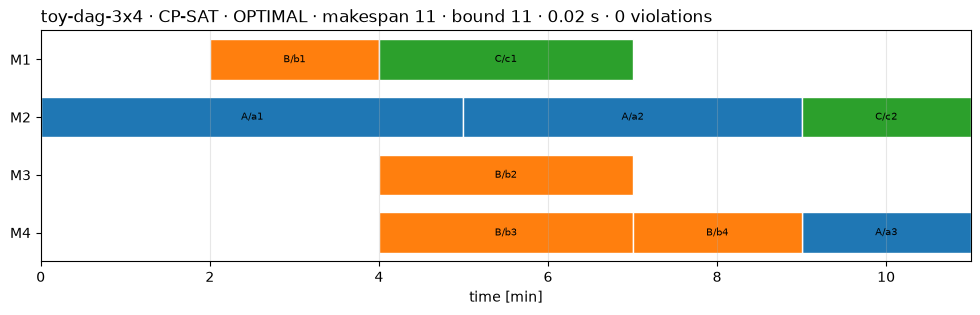

In [8]:
from simulation.planners.cpsat import solve


def gantt_cpsat(ci, name, time_limit=10):
    result = solve(ci, time_limit=time_limit)
    title = (f"{name} · CP-SAT · {result.status} · makespan {result.objective} · bound {result.bound}"
             f" · {result.wall_time:.2f} s · {len(check_schedule(ci, result.schedule))} violations")
    plot_gantt(ci, result.schedule, title=title)
    return result


gantt_cpsat(toy, "toy-dag-3x4");

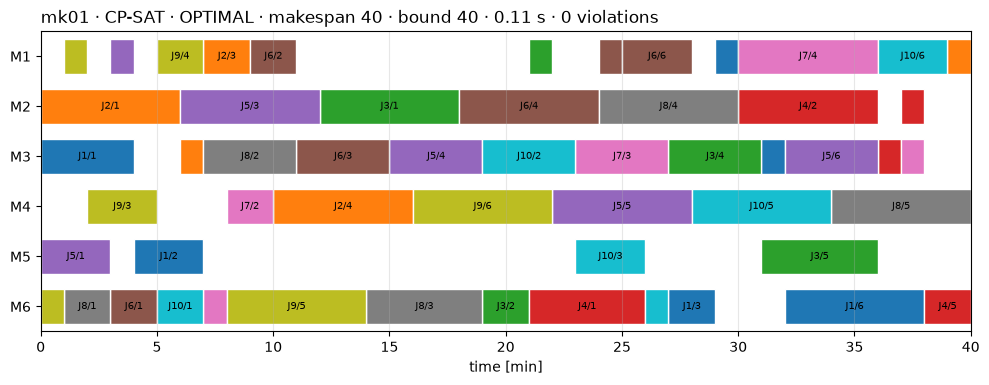

In [9]:
gantt_cpsat(mk01, "mk01");

## Best dispatching rule vs. CP-SAT, cold and warm start

CP-SAT with 10 s and 8 workers, once without and once with the best dispatching schedule as hint (warm start,
`math/12_cp-sat.md`, section 6). Gap = (makespan − bound) / makespan. Own computation; no comparison with best-known
values from the literature yet.

In [10]:
from simulation.planners.dispatching import best_dispatch

print(f"{'':6}{'best rule':>18}{'Cmax':>6} |{'cold':>6}{'bound':>7}{'gap':>7} |{'warm':>6}{'bound':>7}{'gap':>7}")
for path in paths:
    ci = compile_instance(load_fjs(path))
    rule, hint = best_dispatch(ci)
    cold, warm = solve(ci, time_limit=10), solve(ci, time_limit=10, hint=hint)
    cells = "".join(
        f" |{r.objective:>6}{r.bound:>7}{(r.objective - r.bound) / r.objective:>7.1%}" for r in (cold, warm)
    )
    print(f"{path.stem.removeprefix('Brandimarte'):6}{rule:>18}{makespan(hint):>6}" + cells)

               best rule  Cmax |  cold  bound    gap |  warm  bound    gap


Mk1              spt/ect    42 |    40     40   0.0% |    40     40   0.0%


Mk2             mwkr/ect    30 |    26     26   0.0% |    26     26   0.0%


Mk3             fifo/ect   204 |   204    204   0.0% |   204    204   0.0%


Mk4             mwkr/ect    70 |    60     60   0.0% |    60     60   0.0%


Mk5      mwkr/least_load   183 |   173    170   1.7% |   174    170   2.3%


Mk6             mwkr/ect    73 |    63     47  25.4% |    62     39  37.1%


Mk7             mwkr/ect   150 |   144    133   7.6% |   144    133   7.6%


Mk8      mwkr/least_load   523 |   523    523   0.0% |   523    523   0.0%


Mk9             mwkr/ect   311 |   307    307   0.0% |   307    307   0.0%


Mk10            mwkr/ect   227 |   241    183  24.1% |   219    183  16.4%
